# Cromosim - Microscopic model - Tutorial 01 — Building computational domains

This notebook introduces the `cromosim.domain` module using the current **Cromosim 3.1.2** API from the project repository.

The classes are:

- `Domain`: geometry, raster representation, walls and wall-distance field;
- `Destination`: target colors, excluded colors, travel-time field and desired velocity.

> Cromosim represents geometry on a raster grid. Colors therefore have a semantic meaning: for example, black pixels can represent walls and colored pixels can represent destinations.

# 1. Installation and imports

The latest source version can be installed from the project repository. If you already have Cromosim 3.1.1 installed, skip the installation cell.

Cromosim 3.1.2 supports `Python 3.10–3.13`.

In [ ]:
# Uncomment ONE of the following commands if Cromosim is not installed.
#
# Stable package from PyPI:
# %pip install cromosim==3.1.2
#
# or
#
# Current source version from GitHub:
# %pip install "cromosim @ git+https://github.com/sylvain-faure/cromosim.git"

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Ellipse, Rectangle, Polygon

from cromosim.domain import Domain, Destination

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

# 2. Building a Cromosim domain

A `Domain` can start from either:

- a PNG image supplied through `background=...`, or
- a white raster canvas created by Cromosim (`background="White"`).

The parameter `pixel_size` converts pixels into physical coordinates (in meters). For example, with `pixel_size=0.05`, one pixel represents 5 cm.

After the geometry is defined, call:

```python
dom.build_domain()
```

This finalizes the raster representation, identifies wall pixels and computes the distance to walls.

In the examples, we will often use the following colors:

- black `[0, 0, 0]`: walls;
- red `[255, 0, 0]`: west exit;
- blue `[0, 0, 255]`: east exit;
- white `[255, 255, 255]`: free space.

In [25]:
WALL = [0,0,0]

## 2.a — Create a domain from a background image

A background image is convenient when a floor plan already exists. The image can come from a drawing program or an export from software such as `AutoCAD`.

Cromosim requires an image in PNG format, and you must pay attention to its resolution:
- The higher the resolution, the longer it will take to compute the domain
- The size of a pixel must be significantly smaller than the diameter of an individual

When a background image is supplied, `Domain` reads its pixel dimensions automatically. The physical size is then determined by `pixel_size`.

--> domain1:
    dimensions: [0.0,77.9]x[0.0,88.45]
    width: 1558 height: 1769
    background image: event.png
    image of the domain: domain1_domain.png
    wall_colors: [[0, 0, 0]]
    destinations: None


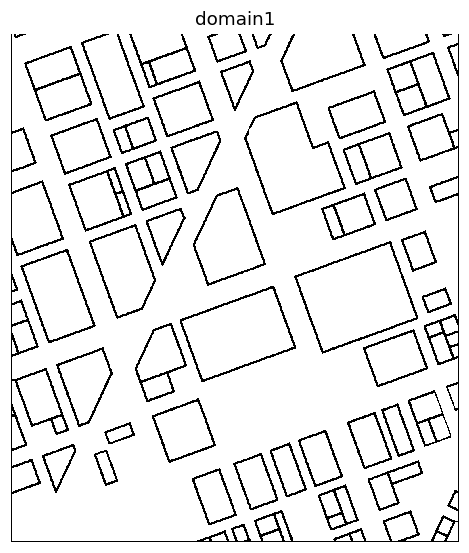

In [26]:
background_file = "event.png"

pixel_size = 0.05  # meters per pixel

dom1 = Domain(
    name="domain1",
    background=background_file,
    pixel_size=pixel_size,
    wall_colors=[WALL],
)

dom1.build_domain()

print(dom1)

dom1.plot(title="domain1")

`build_domain()` computes the wall-distance field automatically when wall pixels exist.

Cromosim stores:

- `dom.wall_distance` — distance to the nearest wall;
- `dom.wall_grad_X`, `dom.wall_grad_Y` — normalized gradient of that distance.

The built-in `plot_wall_dist` method displays both.

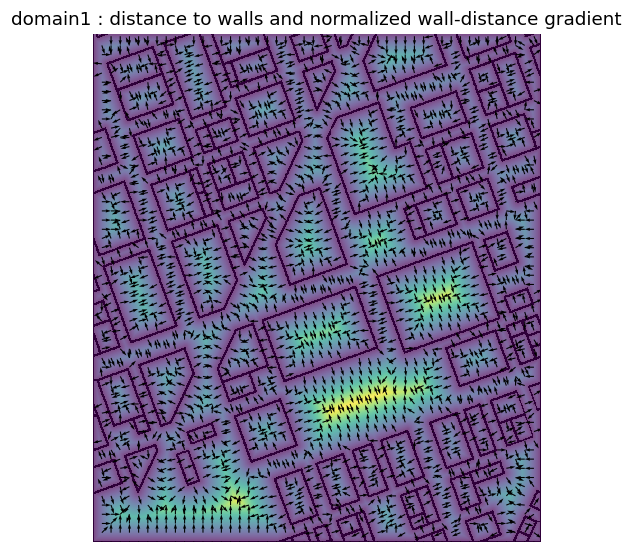

In [28]:
dom1.plot_wall_dist(
    step=32,
    scale=12,
    title="domain1 : distance to walls and normalized wall-distance gradient",
)

## 2.b Create a `Domain` from `matplotlib` shapes

A second approach is to start from a white `Domain` and construct the geometry entirely in Python.

`Domain.add_shape` currently supports:

- `Line2D`;
- `Circle`;
- `Ellipse`;
- `Rectangle`;
- `Polygon`.

This is especially useful for reproducible parametric geometries.

--> domain2:
    dimensions: [0.0,21.0]x[0.0,13.0]
    width: 420 height: 260
    background image: White
    image of the domain: domain2_domain.png
    wall_colors: [[0, 0, 0]]
    destinations: None


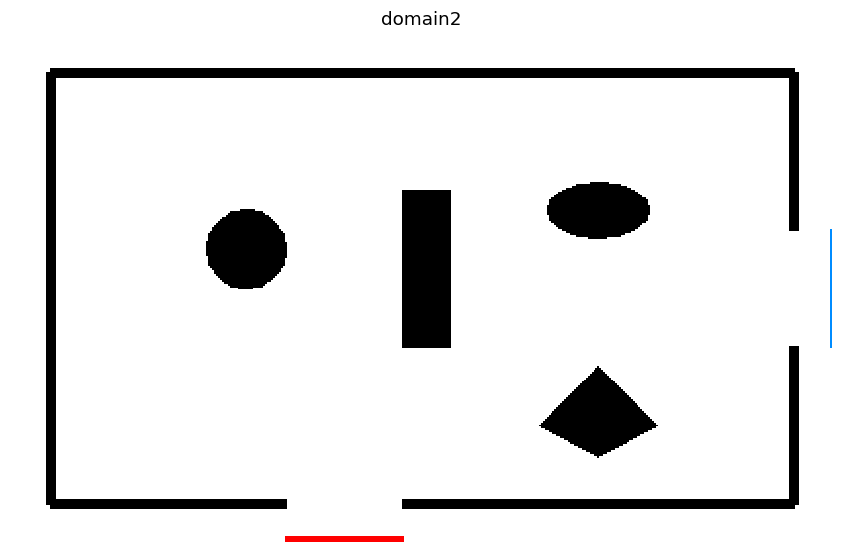

In [45]:
dom2 = Domain(
    name="domain2",
    pixel_size=0.05,
    width=420,
    height=260,
    wall_colors=[WALL],
)

# Room boundary in physical coordinates [m].
# Two gaps are kept in the lower and right walls for the destinations.
wall_lw = 5

# 
dom2.add_shape(Line2D([ 1.0,  1.0], [ 1.0, 12.0], linewidth=wall_lw), outline_color=WALL) # Left wall
dom2.add_shape(Line2D([ 1.0, 20.0], [12.0, 12.0], linewidth=wall_lw), outline_color=WALL) # Top wall
dom2.add_shape(Line2D([20.0, 20.0], [ 1.0,  5.0], linewidth=wall_lw), outline_color=WALL) # Right wall, split around the east exit
dom2.add_shape(Line2D([20.0, 20.0], [ 8.0, 12.0], linewidth=wall_lw), outline_color=WALL)
dom2.add_shape(Line2D([ 1.0,  7.0], [ 1.0,  1.0], linewidth=wall_lw), outline_color=WALL) # Bottom wall, split around the south exit
dom2.add_shape(Line2D([10.0, 20.0], [ 1.0,  1.0], linewidth=wall_lw), outline_color=WALL)

# Interior obstacles using several supported Matplotlib shapes.
dom2.add_shape(Circle((6.0, 7.5), 1.0), outline_color=WALL, fill_color=WALL)
dom2.add_shape(Rectangle((10.0, 5.0), 1.2, 4.0), outline_color=WALL, fill_color=WALL)
dom2.add_shape(Ellipse((15.0, 8.5), 2.6, 1.4), outline_color=WALL, fill_color=WALL)
dom2.add_shape(
    Polygon([[13.5, 3.0], [15.0, 4.5], [16.5, 3.0], [15.0, 2.2]], closed=True),
    outline_color=WALL,
    fill_color=WALL,
)

# Destinations will be simply colored shapes in the raster geometry.
SOUTH_EXIT = [255, 0, 0]
EAST_EXIT  = [0, 140, 255]

dom2.add_shape(Line2D([7.0, 10.0], [0.1, 0.1], linewidth=3), outline_color=SOUTH_EXIT)
dom2.add_shape(Line2D([21.0, 21.0], [5.0, 8.0], linewidth=3), outline_color=EAST_EXIT)

# Finalize the raster representation and wall geometry.
dom2.build_domain()

print(dom2)

dom2.plot(title="domain2")

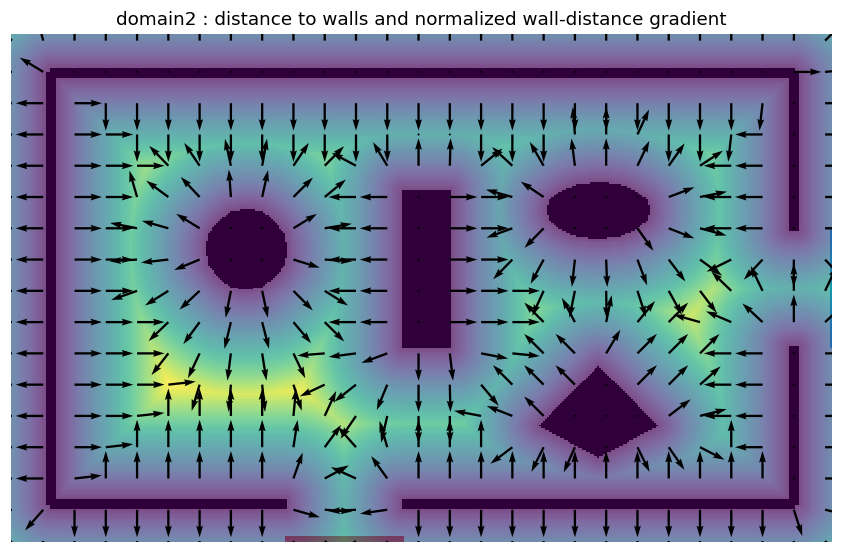

In [46]:
dom2.plot_wall_dist(
    step=16,
    scale=4,
    title="domain2 : distance to walls and normalized wall-distance gradient",
)

Note: You can add Matplotlib plots to a region that has been initialized with a background image.


# 3. Add several destinations

A `Destination` is identified by one or several colors already present in the domain image.

The `excluded_colors` parameter defines colors that the Fast Marching computation cannot cross. Walls therefore usually belong to `excluded_colors`.

For each destination, `dom.add_destination(...)` computes:

- `destination.distance`: distance / travel-time field;
- `destination.desired_velocity_X`;
- `destination.desired_velocity_Y`.

The desired velocity is the normalized opposite gradient of the travel-time field.

In [52]:
# Add destinations for domain2...

south = Destination(
    name="south_exit",
    colors=[SOUTH_EXIT],
    excluded_colors=[WALL],
)

east = Destination(
    name="east_exit",
    colors=[EAST_EXIT],
    excluded_colors=[WALL],
)

dom2.add_destination(south)
dom2.add_destination(east)

print("Available destinations (domain 2):", list(dom2.destinations))

Available destinations (domain 2): ['west_exit', 'east_exit', 'south_exit']


Cromosim provides `plot_desired_velocity`, which overlays the destination travel-time field and the desired-velocity vectors.

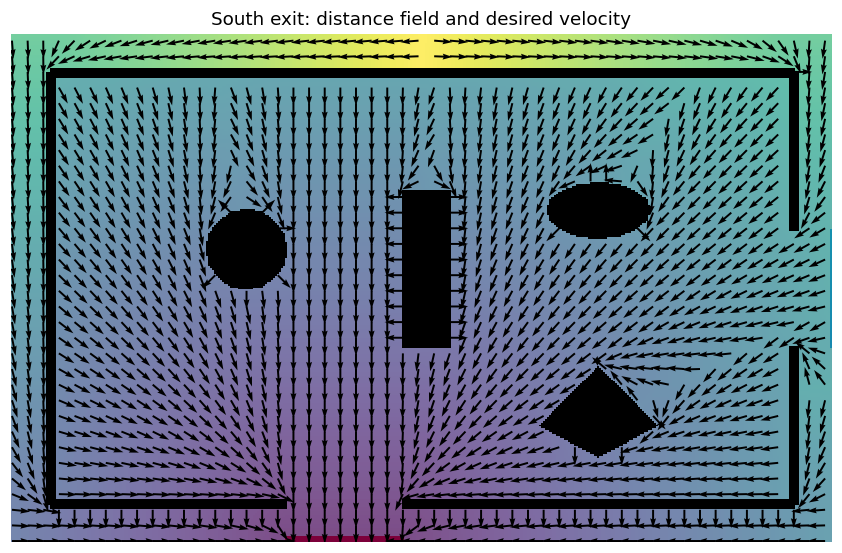

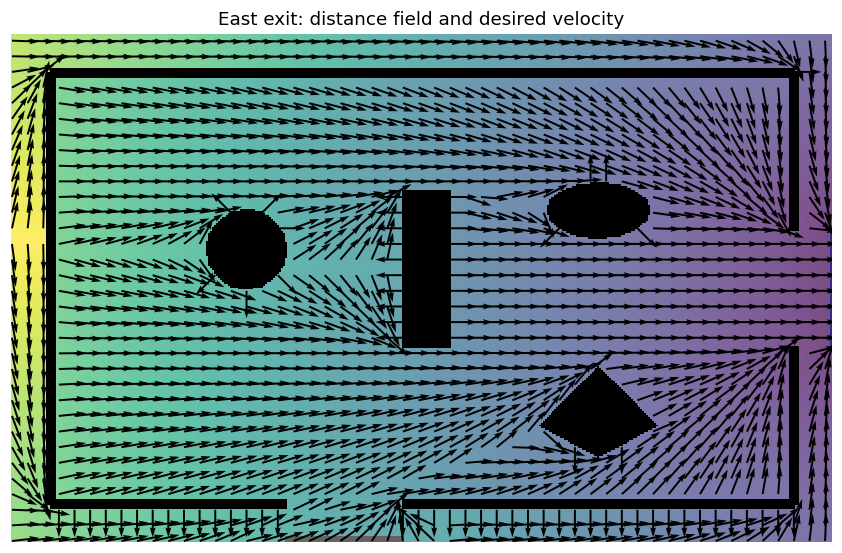

In [66]:
dom2.plot_desired_velocity(
    "south_exit",
    step=8,
    scale=6,
    title="South exit: distance field and desired velocity",
)
plt.show()
dom2.plot_desired_velocity(
    "east_exit",
    step=8,
    scale=4,
    title="East exit: distance field and desired velocity",
)

## 4. Optional: changing the Fast Marching speed

By default, `Destination.fmm_speed` is equal to 1 everywhere. Therefore `Destination.distance` behaves as a geometrical travel distance through the free domain.

A non-uniform `fmm_speed` can model regions that are slower or less attractive. Since Cromosim solves an Eikonal-type travel-time problem, a lower speed increases the travel time through that region and can redirect the desired-velocity field.

A typical workflow is:

```python
speed = np.ones((domain.height, domain.width))
# Modify speed in selected regions here...

destination = Destination(
    name="target",
    colors=[TARGET_COLOR],
    excluded_colors=[WALL],
    fmm_speed=speed,
)
domain.add_destination(destination)
```

The `fmm_speed` array must have exactly the same shape as the domain raster.

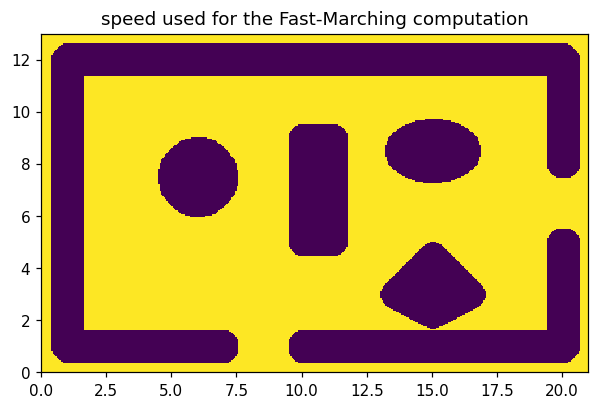

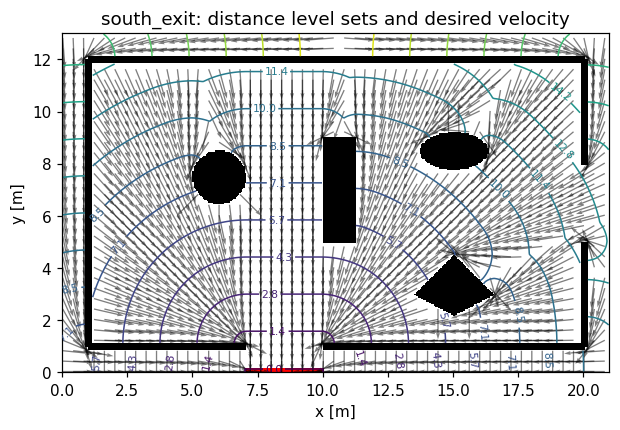

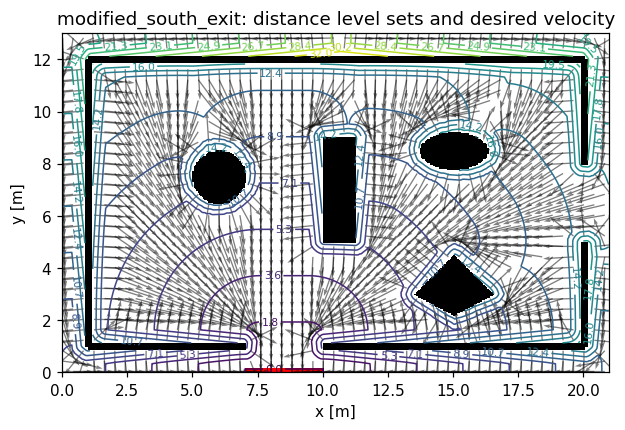

In [96]:
speed = np.where(dom2.wall_distance < 0.5, 0.1, 1.0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(speed, extent=[dom2.xmin, dom2.xmax, dom2.ymin, dom2.ymax], origin="lower", interpolation="nearest")
ax.set_title("speed used for the Fast-Marching computation")
plt.show()

new_destination = Destination(
    name="modified_south_exit",
    colors=[SOUTH_EXIT],
    excluded_colors=[WALL],
    fmm_speed=speed,
)
dom2.add_destination(new_destination)

def plot_destination_contours(domain, destination_name, step=8, n_levels=20):
    
    dest = domain.destinations[destination_name]

    # Mask walls so that neither the scalar field nor vectors are drawn inside them.
    wall_mask = domain.wall_mask.astype(bool)
    distance = np.ma.array(dest.distance, mask=wall_mask)
    u = np.ma.array(dest.desired_velocity_X, mask=wall_mask)
    v = np.ma.array(dest.desired_velocity_Y, mask=wall_mask)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.imshow(
        domain.image,
        extent=[domain.xmin, domain.xmax, domain.ymin, domain.ymax],
        origin="lower",
        interpolation="nearest",
    )

    levels = np.linspace(float(distance.min()), float(distance.max()), n_levels)
    cs = ax.contour(domain.X, domain.Y, distance, levels=levels, linewidths=1.0)
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.1f")

    ax.quiver(
        domain.X[::step, ::step],
        domain.Y[::step, ::step],
        u[::step, ::step],
        v[::step, ::step],
        scale=18, alpha=0.5
    )

    ax.set_aspect("equal")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"{destination_name}: distance level sets and desired velocity")
    plt.show()


plot_destination_contours(dom2, "south_exit")
plot_destination_contours(dom2, "modified_south_exit")


## 5. Now it's your turn to build the domain of your choice...

## References

- Cromosim repository: https://github.com/sylvain-faure/cromosim
- `cromosim.domain` source: https://github.com/sylvain-faure/cromosim/blob/master/cromosim/domain.py
- Domain examples: https://github.com/sylvain-faure/cromosim/tree/master/examples/domain
- Project website: https://www.cromosim.fr